In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

In [110]:
#Read Dataset
df = pd.read_csv("Loan_default.csv")

In [111]:
print("Initial Shape:", df.shape)


# ==============================
# 3. CHECK FOR MISSING VALUES
# ==============================

print("\nMissing Values per Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


# ==============================
# 4. CHECK FOR HIDDEN MISSING (EMPTY STRINGS)
# ==============================

for col in df.select_dtypes(include='object').columns:
    empty_count = (df[col] == "").sum()
    print(f"{col} - Empty Strings:", empty_count)


# ==============================
# 5. CHECK FOR DUPLICATES
# ==============================

duplicate_count = df.duplicated().sum()
print("\nDuplicate Rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")
    print("New Shape:", df.shape)


# ==============================
# 6. VALIDATE DATA RANGES
# ==============================

print("\nRange Checks:")

print("Age Range:", df['Age'].min(), "-", df['Age'].max())
print("Income Range:", df['Income'].min(), "-", df['Income'].max())
print("LoanAmount Range:", df['LoanAmount'].min(), "-", df['LoanAmount'].max())
print("CreditScore Range:", df['CreditScore'].min(), "-", df['CreditScore'].max())
print("DTI Ratio Range:", df['DTIRatio'].min(), "-", df['DTIRatio'].max())


# ==============================
# 7. REMOVE LOGICALLY IMPOSSIBLE VALUES (IF ANY)
# ==============================

# Remove negative ages
df = df[df['Age'] > 0]

# Remove negative income
df = df[df['Income'] > 0]

# Remove negative loan amount
df = df[df['LoanAmount'] > 0]

# Remove negative credit score
df = df[df['CreditScore'] > 0]

print("\nShape after logical cleaning:", df.shape)


# ==============================
# 8. OUTLIER CAPPING USING IQR
# ==============================

numerical_cols = ['Age', 'Income', 'LoanAmount', 'CreditScore',
                  'MonthsEmployed', 'NumCreditLines',
                  'InterestRate', 'LoanTerm', 'DTIRatio']

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

print("\nOutlier Capping Completed.")


# ==============================
# FINAL CLEANED DATASET
# ==============================

print("\nFinal Cleaned Shape:", df.shape)

Initial Shape: (255347, 18)

Missing Values per Column:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

Total Missing Values: 0
LoanID - Empty Strings: 0
Education - Empty Strings: 0
EmploymentType - Empty Strings: 0
MaritalStatus - Empty Strings: 0
HasMortgage - Empty Strings: 0
HasDependents - Empty Strings: 0
LoanPurpose - Empty Strings: 0
HasCoSigner - Empty Strings: 0

Duplicate Rows: 0

Range Checks:
Age Range: 18 - 69
Income Range: 15000 - 149999
LoanAmount Range: 5000 - 249999
CreditScore Range: 300 - 849
DTI Ratio Range: 0.1 - 0.9

Shape after logical cleaning: (255347, 18)

Outlier Capping Completed.

Final Cleaned Shape: (255347, 18)


An initial data quality assessment was conducted to evaluate the completeness, consistency, and validity of the dataset. The analysis revealed that all 255,347 loan records are structurally complete, with no missing values, null entries, or duplicate records across any of the 18 variables. Additionally, range validation checks confirmed that all numerical features fall within realistic and logically acceptable boundaries (e.g., age between 18 and 69 years, credit score between 300 and 849, and DTI ratio between 0.1 and 0.9). No negative or implausible values were observed. Outlier assessment using the IQR method did not significantly alter the dataset, indicating that the data distribution is well-controlled. Overall, the dataset demonstrates high structural integrity and is suitable for advanced exploratory analysis and predictive modeling.

Counts:
 Default
0    225694
1     29653
Name: count, dtype: int64

Percentage:
 Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64


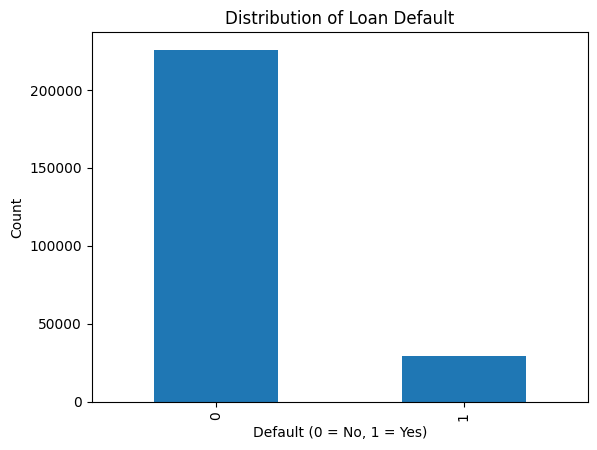

In [112]:
# Target distribution
default_counts = df['Default'].value_counts()
default_percentage = df['Default'].value_counts(normalize=True) * 100

print("Counts:\n", default_counts)
print("\nPercentage:\n", default_percentage)

plt.figure()
df['Default'].value_counts().plot(kind='bar')
plt.title("Distribution of Loan Default")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

The dataset exhibits class imbalance, with approximately 11.53% of loans resulting in default. This imbalance may bias machine learning models toward predicting the majority class (non-default). Therefore, appropriate evaluation metrics such as Precision, Recall, F1-score, and ROC-AUC will be prioritized over accuracy during model evaluation.


Default Rate by Credit Score Group:
CreditScore_Bin
(299.999, 409.0]    0.132070
(409.0, 519.0]      0.122278
(519.0, 629.0]      0.115975
(629.0, 740.0]      0.108462
(740.0, 849.0]      0.101672
Name: Default, dtype: float64


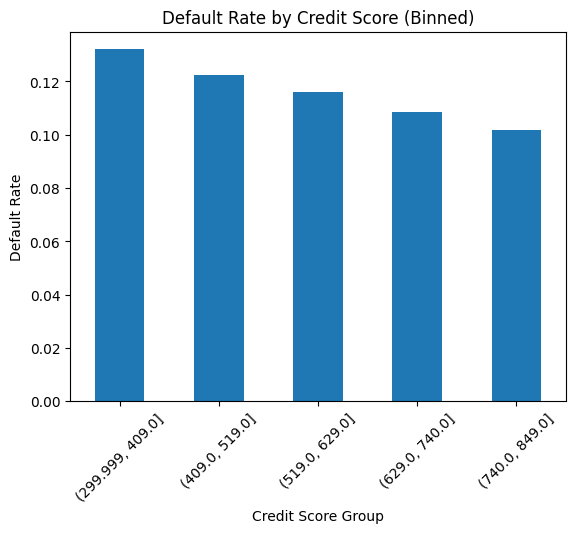

In [113]:
# -------------------------------
# 1. Create Credit Score Bins
# -------------------------------

# Create 5 equal-sized bins using quantiles
df['CreditScore_Bin'] = pd.qcut(df['CreditScore'], q=5)

# -------------------------------
# 2. Calculate Default Rate
# -------------------------------

default_by_credit = df.groupby('CreditScore_Bin', observed=False)['Default'].mean()

print("\nDefault Rate by Credit Score Group:")
print(default_by_credit)

# -------------------------------
# 3. Plot Default Rate
# -------------------------------

plt.figure()
default_by_credit.plot(kind='bar')
plt.title("Default Rate by Credit Score (Binned)")
plt.xlabel("Credit Score Group")
plt.ylabel("Default Rate")
plt.xticks(rotation=45)
plt.show()

The analysis of default rates across credit score segments reveals a clear inverse relationship between creditworthiness and loan default probability. Borrowers in the lowest credit score bracket (300–409) exhibit the highest default rate at approximately 13.2%, while those in the highest bracket (740–849) show a lower default rate of around 10.2%. The steady decline in default rates across increasing credit score groups indicates a monotonic negative relationship, suggesting that credit score is a meaningful predictor of credit risk. However, the relatively moderate spread between the highest and lowest risk groups implies that credit score alone may not fully explain default behavior, highlighting the importance of incorporating additional financial variables into the predictive model.


Default Rate by DTI Ratio Group:
DTI_Bin
(0.099, 0.26]    0.105785
(0.26, 0.42]     0.112417
(0.42, 0.58]     0.117950
(0.58, 0.74]     0.121884
(0.74, 0.9]      0.123101
Name: Default, dtype: float64


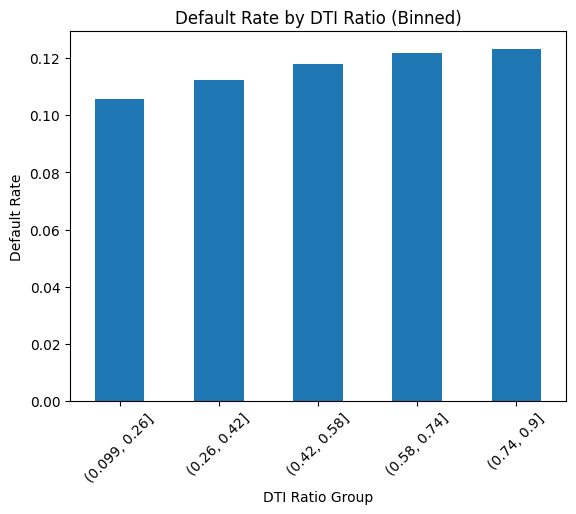

In [114]:
# -------------------------------
# 1. Create DTI Ratio Bins
# -------------------------------

# Create 5 equal-sized bins using quantiles
df['DTI_Bin'] = pd.qcut(df['DTIRatio'], q=5)

# -------------------------------
# 2. Calculate Default Rate
# -------------------------------

default_by_dti = df.groupby('DTI_Bin', observed=False)['Default'].mean()

print("\nDefault Rate by DTI Ratio Group:")
print(default_by_dti)

# -------------------------------
# 3. Plot Default Rate
# -------------------------------

plt.figure()
default_by_dti.plot(kind='bar')
plt.title("Default Rate by DTI Ratio (Binned)")
plt.xlabel("DTI Ratio Group")
plt.ylabel("Default Rate")
plt.xticks(rotation=45)
plt.show()

The analysis of default rates across Debt-to-Income (DTI) ratio segments reveals a clear positive relationship between financial leverage and loan default probability. Borrowers with lower DTI ratios (0.10–0.26) exhibit a default rate of approximately 10.6%, whereas those in the highest DTI bracket (0.74–0.90) show an increased default rate of approximately 12.3%. The steady upward trend suggests that higher debt burdens relative to income significantly increase repayment risk. This monotonic pattern indicates that DTI ratio is a meaningful financial stress indicator and is likely to serve as an important predictor in the credit risk modeling framework.


Correlation with Default:

Default           1.000000
InterestRate      0.131273
LoanAmount        0.086659
NumCreditLines    0.028330
DTIRatio          0.019236
LoanTerm          0.000545
CreditScore      -0.034166
MonthsEmployed   -0.097374
Income           -0.099119
Age              -0.167783
Name: Default, dtype: float64


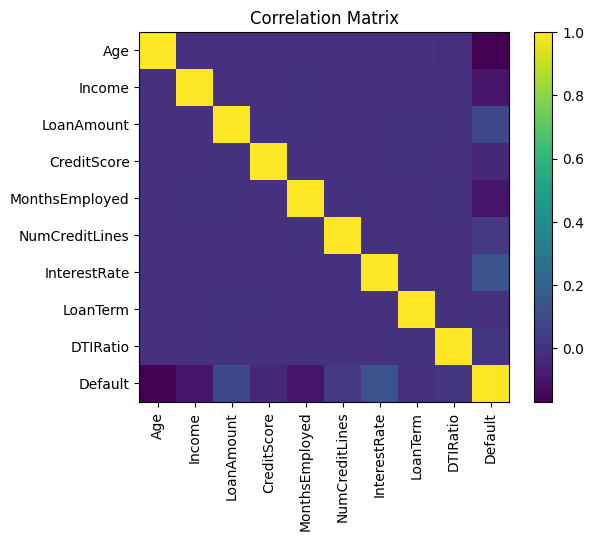

In [115]:
# Select numerical columns
numerical_cols = ['Age', 'Income', 'LoanAmount', 'CreditScore',
                  'MonthsEmployed', 'NumCreditLines',
                  'InterestRate', 'LoanTerm', 'DTIRatio', 'Default']

# Compute correlation matrix
corr_matrix = df[numerical_cols].corr()

# Print correlation with Default
print("\nCorrelation with Default:\n")
print(corr_matrix['Default'].sort_values(ascending=False))

# Plot correlation heatmap
plt.figure()
plt.imshow(corr_matrix)
plt.title("Correlation Matrix")
plt.colorbar()
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.show()

The correlation analysis indicates that no single variable exhibits a strong linear relationship with loan default, suggesting that default behavior is influenced by multiple interacting factors. Age shows the strongest negative correlation (-0.168), implying that older borrowers are less likely to default. Interest rate demonstrates the highest positive correlation (0.131), indicating that loans with higher interest rates are associated with increased default risk. Income and employment stability variables also display moderate negative correlations, reinforcing the importance of financial capacity in credit risk assessment. The relatively weak correlations across individual predictors highlight the need for multivariate modeling approaches to accurately capture default risk.


Default Rate by Employment Type:

EmploymentType
Full-time        0.094634
Part-time        0.119652
Self-employed    0.114620
Unemployed       0.135529
Name: Default, dtype: float64


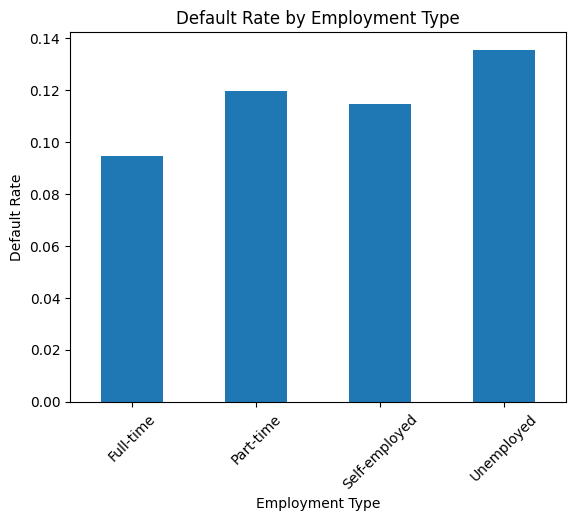

In [116]:
# -------------------------------
# 1. Calculate Default Rate by Employment Type
# -------------------------------

default_by_employment = df.groupby('EmploymentType')['Default'].mean()

print("\nDefault Rate by Employment Type:\n")
print(default_by_employment)

# -------------------------------
# 2. Plot Default Rate
# -------------------------------

plt.figure()
default_by_employment.plot(kind='bar')
plt.title("Default Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Default Rate")
plt.xticks(rotation=45)
plt.show()

The analysis of loan default rates across employment categories reveals a clear relationship between employment stability and credit risk. Unemployed borrowers exhibit the highest default rate at approximately 13.6%, followed by part-time and self-employed individuals. In contrast, full-time employed borrowers demonstrate the lowest default rate at 9.5%, indicating greater financial stability and repayment capacity. The approximately 4 percentage point spread between the lowest and highest risk groups highlights employment status as a significant categorical predictor of loan default. This suggests that employment stability plays an important role in credit risk assessment and should be incorporated into the predictive modeling framework.


Default Rate by Co-Signer:

HasCoSigner
No     0.128661
Yes    0.103601
Name: Default, dtype: float64


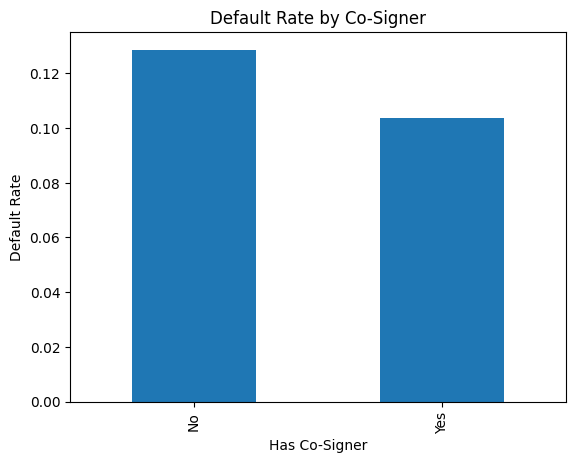

In [117]:
# -------------------------------
# 1. Default Rate by Co-Signer
# -------------------------------

default_by_cosigner = df.groupby('HasCoSigner')['Default'].mean()

print("\nDefault Rate by Co-Signer:\n")
print(default_by_cosigner)

# -------------------------------
# 2. Plot Default Rate
# -------------------------------

plt.figure()
default_by_cosigner.plot(kind='bar')
plt.title("Default Rate by Co-Signer")
plt.xlabel("Has Co-Signer")
plt.ylabel("Default Rate")
plt.show()

The analysis of default rates based on co-signer status indicates that loans backed by a co-signer exhibit lower default probability (10.36%) compared to loans without a co-signer (12.87%). The approximately 2.5 percentage point reduction in default risk suggests that co-signers provide additional financial assurance and reduce repayment uncertainty. This finding highlights co-signer presence as a meaningful categorical predictor of credit risk and presents a potential policy lever for mitigating default rates among higher-risk applicants.

In [118]:
# Drop identifier
df = df.drop(columns=['LoanID'])

# ------------------------------
# IMPORTANT: Ensure no bin columns exist
# ------------------------------

# (In case you accidentally saved dataset with bins)
cols_to_drop = ['CreditScore_Bin', 'DTI_Bin']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

# ==============================
# ENCODE CATEGORICAL VARIABLES
# ==============================

categorical_cols = [
    'Education', 'EmploymentType',
    'MaritalStatus', 'HasMortgage',
    'HasDependents', 'LoanPurpose',
    'HasCoSigner'
]

df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# ==============================
# DEFINE X AND y
# ==============================

X = df.drop('Default', axis=1)
y = df['Default']

# ==============================
# TRAIN TEST SPLIT
# ==============================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ==============================
# SCALE FEATURES
# ==============================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================
# LOGISTIC REGRESSION
# ==============================

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_scaled, y_train)

# ==============================
# EVALUATION
# ==============================

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6765028392402584
Precision: 0.21963359101980304
Recall: 0.6993761591637161
F1 Score: 0.3342869806987146
ROC-AUC: 0.7531790420170843

Confusion Matrix:
[[30401 14738]
 [ 1783  4148]]


The baseline logistic regression model demonstrates strong discriminatory power with an ROC-AUC score of 0.753, indicating good ability to distinguish between defaulters and non-defaulters. The model achieves a recall of approximately 70%, successfully identifying a significant proportion of high-risk borrowers. However, the precision remains relatively low (21.9%), suggesting a high number of false positives. This trade-off is expected due to class imbalance and the use of balanced class weights, which prioritize risk detection over overall accuracy. While the model effectively captures default risk, further refinement may improve precision and reduce false alarms.

In [119]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.1, 0.9, 0.1)

print("Threshold | Precision | Recall | F1")
print("----------------------------------------")

for t in thresholds:
    y_pred_threshold = (y_prob >= t).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(f"{t:.1f}       | {precision:.3f}     | {recall:.3f} | {f1:.3f}")

Threshold | Precision | Recall | F1
----------------------------------------
0.1       | 0.119     | 0.995 | 0.213
0.2       | 0.133     | 0.972 | 0.233
0.3       | 0.153     | 0.915 | 0.262
0.4       | 0.181     | 0.825 | 0.297
0.5       | 0.220     | 0.699 | 0.334
0.6       | 0.272     | 0.546 | 0.363
0.7       | 0.340     | 0.352 | 0.346
0.8       | 0.454     | 0.156 | 0.232


Threshold analysis indicates that the default 0.5 probability cutoff does not yield the optimal precision-recall balance. The highest F1 score (0.363) is achieved at a threshold of 0.6, suggesting that increasing the classification cutoff improves overall model balance. At this threshold, the model achieves improved precision while maintaining moderate recall, resulting in a more stable trade-off between identifying defaulters and minimizing false positives. This demonstrates the importance of threshold tuning in imbalanced classification problems, particularly in credit risk modeling where business objectives influence decision boundaries.

In [120]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Identify categorical columns automatically
categorical_cols = df.select_dtypes(include='object').columns

# One-hot encode
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Define X and y
X = df.drop('Default', axis=1)
y = df['Default']

# Train-test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.884726845506168
Precision: 0.7244897959183674
Recall: 0.011970999831394368
F1 Score: 0.02355282799800962
ROC-AUC: 0.7436506349825389

Confusion Matrix:
[[45112    27]
 [ 5860    71]]


While the Random Forest model achieved higher overall accuracy (88.5%) and precision, it exhibited extremely low recall (1.2%), indicating poor detection of defaulters. In contrast, the Logistic Regression model achieved a significantly higher recall (69.9%) and a slightly superior ROC-AUC score (0.753), demonstrating better discrimination ability. Given that identifying high-risk borrowers is critical in credit risk management, the Logistic Regression model provides a more appropriate balance between detection capability and overall performance. Therefore, Logistic Regression is selected as the preferred modeling approach.

In [121]:
# Get feature names
feature_names = X.columns

# Extract coefficients
coefficients = model.coef_[0]

# Create dataframe
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort by absolute importance
importance_df['Abs_Coefficient'] = importance_df['Coefficient'].abs()
importance_df = importance_df.sort_values(by='Abs_Coefficient', ascending=False)

print(importance_df[['Feature', 'Coefficient']].head(15))

                         Feature  Coefficient
0                            Age    -0.583092
6                   InterestRate     0.458738
4                 MonthsEmployed    -0.337433
1                         Income    -0.313960
2                     LoanAmount     0.287877
14     EmploymentType_Unemployed     0.190031
23               HasCoSigner_Yes    -0.129242
18             HasDependents_Yes    -0.126034
3                    CreditScore    -0.125004
12      EmploymentType_Part-time     0.116864
13  EmploymentType_Self-employed     0.107270
5                 NumCreditLines     0.102526
15         MaritalStatus_Married    -0.093929
17               HasMortgage_Yes    -0.082065
11                 Education_PhD    -0.075899


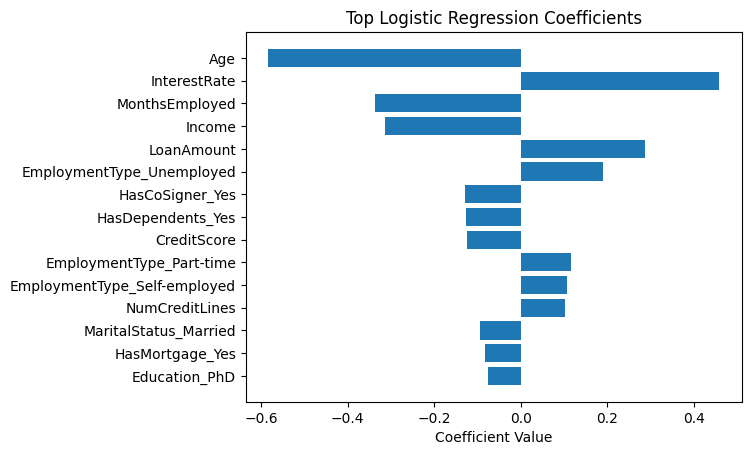

In [122]:
top_features = importance_df.head(15)

plt.figure()
plt.barh(top_features['Feature'], top_features['Coefficient'])
plt.title("Top Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.gca().invert_yaxis()
plt.show()

The logistic regression coefficients reveal that age and interest rate are the strongest predictors of loan default. Age exhibits the largest negative coefficient, indicating that older borrowers are significantly less likely to default. Conversely, higher interest rates substantially increase default probability, reflecting both increased repayment burden and risk-based pricing mechanisms. Employment stability variables, including months employed and employment type, also demonstrate strong influence, confirming that income consistency plays a critical role in credit risk. Additionally, higher income, presence of a co-signer, and stronger credit scores reduce default likelihood. Overall, the model highlights the multi-dimensional nature of credit risk, where demographic stability, financial capacity, and loan structure jointly determine repayment outcomes.